# TPE · EPA Fuel Economy 2025
## 1. Análisis exploratorio inicial

Se examinan la estructura, los atributos, las distribuciones, los valores faltantes y los valores extremos de la base. El objetivo es comprender los datos antes de realizar la limpieza y plantear las hipótesis.

### 1.1. Contexto y lectura de los datos

El conjunto contiene resultados de ensayos de vehículos de año modelo 2025 realizados por la Environmental Protection Agency (EPA) de Estados Unidos y por fabricantes que reportan sus resultados al organismo. Estos ensayos forman parte del proceso de determinación de las estimaciones oficiales de economía de combustible.

La economía de combustible indica la distancia recorrida por unidad de combustible. En MPG, un valor mayor representa una mayor eficiencia. El año modelo no equivale a la fecha en que se realizó cada ensayo.

Se lee la hoja `Sheet1` del Excel original, conservado en `data/`. Se muestran las primeras filas y un resumen de las columnas para comprobar que la lectura sea correcta.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

archivo = "data/25-testcar-2026-01-21.xlsx"
datos = pd.read_excel(archivo, sheet_name='Sheet1')

print('Filas:', datos.shape[0], '| Columnas:', datos.shape[1])
display(datos.head())
datos.info()

Filas: 4287 | Columnas: 67


,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,...,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   object 
 2   Veh Mfr Code                    4287 non-null   object 
 3   Represented Test Veh Make       4287 non-null   object 
 4   Represented Test Veh Model      4287 non-null   object 
 5   Test Vehicle ID                 4287 non-null   object 
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   float64
 8   Actual Tested Testgroup         4287 non-null   object 
 9   Vehicle Type                    4287 non-null   object 
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     42

### 1.2. Unidad de observación y repeticiones

Cada fila corresponde al registro de un ensayo de una configuración. La combinación `Veh Mfr Code`, `Test Vehicle ID` y `Test Veh Configuration #` identifica una configuración. Un mismo vehículo puede tener varias configuraciones y ensayos, por lo que no se debe interpretar la cantidad de filas como cantidad de vehículos diferentes.

Se cuentan las configuraciones y los ensayos distintos y se comprueba si existen filas completamente duplicadas.

In [2]:
clave_config = ['Veh Mfr Code', 'Test Vehicle ID', 'Test Veh Configuration #']

print('Configuraciones distintas:', datos[clave_config].drop_duplicates().shape[0])
print('Números de ensayo distintos:', len(datos['Test Number'].value_counts()))
print('Filas completamente duplicadas:', datos.duplicated().sum())

# Mostramos un ejemplo de un mismo ensayo registrado en más de una fila.
repetidos = datos[datos['Test Number'].duplicated(keep=False)]
ejemplo = repetidos['Test Number'].iloc[0]
columnas = ['Test Number'] + clave_config + ['Test Category', 'Aftertreatment Device Desc']
display(datos.loc[datos['Test Number'] == ejemplo, columnas])

Configuraciones distintas: 1448
Números de ensayo distintos: 4014
Filas completamente duplicadas: 0


,Test Number,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Test Category,Aftertreatment Device Desc
12,SBMX10086268,BMX,8D89453,0,FTP,Other
13,SBMX10086268,BMX,8D89453,0,FTP,Three-way catalyst


La base contiene **4.287 registros, 1.448 configuraciones y 4.014 números de ensayo distintos**. No hay filas completamente idénticas. El ejemplo muestra un ensayo repetido con distinto dispositivo de postratamiento: repetir el número de ensayo no equivale a tener filas idénticas.

Las filas se conservan durante la exploración. El tratamiento de las repeticiones y la unidad de análisis deberán definirse antes de los análisis posteriores, porque algunos ensayos aparecen más veces que otros.

### 1.3. Caracterización de los atributos

Las 67 columnas incluyen identificadores, categorías, características técnicas, condiciones de ensayo y resultados. Se distinguen los tipos computacionales que muestra `info()` de su significado estadístico.

| Grupo | Ejemplos de atributos | Tipo e interpretación |
| --- | --- | --- |
| Identificación | `Veh Mfr Code`, `Test Vehicle ID`, `Test Veh Configuration #`, `Test Number` | Identifican fabricantes, vehículos, configuraciones y ensayos; no son medidas para promediar. |
| Año modelo | `Model Year` | Variable temporal discreta; toma el valor 2025 en toda la base. |
| Características cualitativas | Fabricante, modelo, `Vehicle Type`, transmisión, tracción y combustible | Variables nominales. Los códigos numéricos también representan categorías. |
| Conteos | `# of Cylinders and Rotors`, `# of Gears` | Variables cuantitativas discretas. |
| Características mecánicas | Cilindrada, potencia y peso equivalente | Medidas cuantitativas, expresadas en L, HP y lb. |
| Condiciones y métodos | Procedimiento, categoría, origen del ensayo, indicadores ADFE y promediado | Categorías y campos que describen cómo se obtuvo el resultado. |
| Economía de combustible | `RND_ADJ_FE`, `FE Bag 1` a `FE Bag 4` | Medidas cuantitativas; `FE_UNIT` declara MPG en todos los registros. |
| Emisiones | THC, CO, CO2, NOx, PM, CH4 y N2O | Medidas cuantitativas expresadas en g/mi. |
| Otros parámetros | Relaciones mecánicas, coeficientes del dinamómetro, postratamiento y ponderación | Información técnica complementaria; algunos campos solo corresponden a ciertos tipos de ensayo. |

Para describir la composición de la base se muestran las frecuencias de las categorías principales. Los porcentajes se calculan sobre el total de registros, incluyendo las ausencias.

,Registros,Porcentaje
Vehicle Type,,
Truck,2030,47.35
Car,1631,38.05
Both,626,14.60


,Registros,Porcentaje
Test Fuel Type Description,,
Tier 2 Cert Gasoline,3236,75.48
Electricity,654,15.26
Cold CO Regular (Tier 2),160,3.73
Federal Cert Diesel 7-15 PPM Sulfur,150,3.50
Cold CO Premium (Tier 2),57,1.33
E85 (85% Ethanol 15% EPA Unleaded Gasoline),12,0.28
Hydrogen 5,10,0.23
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),3,0.07
Cold CO E10 Regular Gasoline (Tier 3),2,0.05


,Registros,Porcentaje
Test Category,,
FTP,1577,36.79
HWY,1340,31.26
CD,695,16.21
US06,412,9.61
SC03,263,6.13


,Registros,Porcentaje
Drive System Description,,
All Wheel Drive,1459,34.03
"2-Wheel Drive, Front",1393,32.49
"2-Wheel Drive, Rear",957,22.32
4-Wheel Drive,405,9.45
Part-time 4-Wheel Drive,73,1.70


,Registros,Porcentaje
Tested Transmission Type,,
Automatic,1639,38.23
Semi-Automatic,1220,28.46
Continuously Variable,490,11.43
Automated Manual- Selectable (e.g. Automated Manual with paddles),485,11.31
Selectable Continuously Variable (e.g. CVT with paddles),171,3.99
Manual,128,2.99
Other,102,2.38
Automated Manual,52,1.21


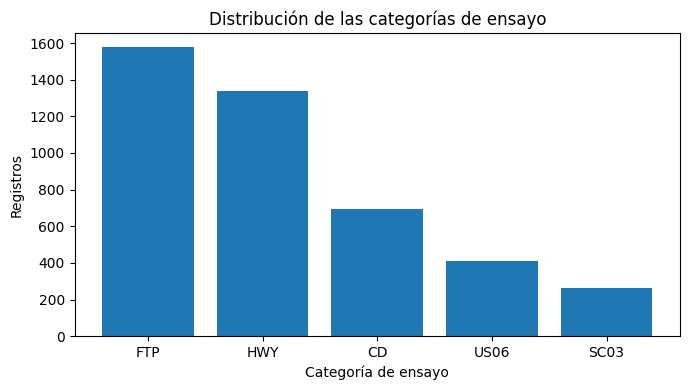

In [3]:
categoricas = ['Vehicle Type', 'Test Fuel Type Description', 'Test Category',
               'Drive System Description', 'Tested Transmission Type']

for columna in categoricas:
    frecuencias = datos[columna].value_counts(dropna=False)
    tabla = pd.DataFrame({
        'Registros': frecuencias,
        'Porcentaje': 100 * frecuencias / len(datos)
    })
    display(tabla.round(2))

frecuencias_cat = datos['Test Category'].value_counts()
plt.figure(figsize=(7, 4))
plt.bar(frecuencias_cat.index, frecuencias_cat.values)
plt.xlabel('Categoría de ensayo')
plt.ylabel('Registros')
plt.title('Distribución de las categorías de ensayo')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Predominan `Tier 2 Cert Gasoline` (**3.236 registros**), `Truck` (**2.030**) y las categorías de ensayo `FTP` (**1.577**) y `HWY` (**1.340**). Estas frecuencias describen los registros disponibles, no el parque automotor ni las ventas de vehículos.

### 1.4. Valores nulos

Se calcula la cantidad y el porcentaje de faltantes por columna. Un cero es un valor registrado y se diferencia de una ausencia. Luego se revisan dos patrones relevantes: la disponibilidad de información ADFE según el método y la ausencia de cilindros según el combustible.

In [4]:
faltantes = pd.DataFrame({
    'Nulos': datos.isna().sum(),
    'Porcentaje': 100 * datos.isna().sum() / len(datos)
})
display(faltantes[faltantes['Nulos'] > 0].sort_values('Nulos', ascending=False).round(2))

# Los campos ADFE corresponden a economía derivada analíticamente.
adfe = ['ADFE Test Number', 'ADFE Total Road Load HP',
        'ADFE Equiv. Test Weight (lbs.)', 'ADFE N/V Ratio']
print('Porcentaje de nulos ADFE según el método:')
display(datos[adfe].isna().groupby(datos['Analytically Derived FE?']).mean() * 100)

print('Nulos en cilindros según combustible:')
nulos_cilindros = datos['# of Cylinders and Rotors'].isna()
print(nulos_cilindros.groupby(datos['Test Fuel Type Description']).sum())

,Nulos,Porcentaje
Averaging Weighting Factor,4212,98.25
Averaging Group ID,4212,98.25
ADFE Total Road Load HP,4075,95.05
ADFE Equiv. Test Weight (lbs.),4075,95.05
ADFE N/V Ratio,4075,95.05
ADFE Test Number,4075,95.05
FE Bag 4,3899,90.95
PM (g/mi),3898,90.93
FE Bag 3,2834,66.11
FE Bag 2,2423,56.52


Porcentaje de nulos ADFE según el método:


,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio
Analytically Derived FE?,,,,
No,100.0,100.0,100.0,100.0
Yes,0.0,0.0,0.0,0.0


Nulos en cilindros según combustible:
Test Fuel Type Description
CARB LEV3 E10 Premium Gasoline                     0
CARB LEV3 E10 Regular Gasoline                     0
Cold CO E10 Regular Gasoline (Tier 3)              0
Cold CO Premium (Tier 2)                           0
Cold CO Regular (Tier 2)                           0
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        0
Electricity                                      654
Federal Cert Diesel 7-15 PPM Sulfur                0
Hydrogen 5                                        10
Tier 2 Cert Gasoline                               6
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)      0
Name: # of Cylinders and Rotors, dtype: int64


#### Otras formas de representar un faltante

Además de los nulos que reconoce Pandas, buscamos espacios, guiones y palabras que podrían indicar ausencia de información. Para eso volvemos a leer el Excel con `keep_default_na=False`: así podemos revisar las marcas originales sin que se conviertan automáticamente en `NaN`. Esta lectura se guarda aparte y no cambia `datos`.

Contamos las marcas buscadas en cada columna. Para comparar los textos, ignoramos las mayúsculas y los espacios al principio y al final. Después buscamos algunos valores numéricos que podrían haberse usado como marcas. Encontrarlos no demuestra que sean faltantes: también pueden ser valores válidos. La búsqueda se limita a las marcas elegidas; no descarta otras representaciones.

In [5]:
datos_marcas = pd.read_excel(archivo, sheet_name='Sheet1', keep_default_na=False)

marcas_texto = ['', '-', '--', '?', 'na', 'n/a', 'n.a.', 'nan', 'null',
                'none', 'unknown', 'not applicable', 'n/d', 's/d',
                'sin dato', 'sin datos']
revision_texto = []
for columna in datos_marcas.columns:
    valores = datos_marcas[columna].astype(str).str.strip().str.lower()
    frecuencias = valores.value_counts()
    for marca in marcas_texto:
        if marca in frecuencias.index:
            revision_texto.append([columna, '(vacío o espacios)' if marca == '' else marca,
                                   frecuencias[marca]])

print('Marcas de texto encontradas:')
display(pd.DataFrame(revision_texto, columns=['Columna', 'Marca buscada', 'Registros']))
print('Total de marcas de texto:', sum(fila[2] for fila in revision_texto))
print('Total de nulos reconocidos en la lectura habitual:', datos.isna().sum().sum())

marcas_numericas = [-1, -9, -99, -999, 99.999, 9999, 99999, 9999.9999999]
revision_numerica = []
for columna in datos.select_dtypes(include='number').columns:
    frecuencias = datos[columna].value_counts()
    for marca in marcas_numericas:
        if marca in frecuencias.index:
            revision_numerica.append([columna, str(marca), frecuencias[marca]])

print('Valores numéricos para revisar; no se reemplazan en esta búsqueda:')
tabla_marcas_numericas = pd.DataFrame(revision_numerica,
                                    columns=['Columna', 'Valor buscado', 'Registros'])
display(tabla_marcas_numericas)

Marcas de texto encontradas:


,Columna,Marca buscada,Registros
0,# of Cylinders and Rotors,(vacío o espacios),670
1,ADFE Test Number,(vacío o espacios),4075
2,ADFE Total Road Load HP,(vacío o espacios),4075
3,ADFE Equiv. Test Weight (lbs.),(vacío o espacios),4075
4,ADFE N/V Ratio,(vacío o espacios),4075
5,THC (g/mi),(vacío o espacios),958
6,CO (g/mi),(vacío o espacios),884
7,CO2 (g/mi),(vacío o espacios),724
8,NOx (g/mi),(vacío o espacios),885
9,PM (g/mi),(vacío o espacios),3898


Total de marcas de texto: 51153
Total de nulos reconocidos en la lectura habitual: 51153
Valores numéricos para revisar; no se reemplazan en esta búsqueda:


,Columna,Valor buscado,Registros
0,Test Veh Displacement (L),99.999,95
1,PM (g/mi),9999.9999999,15
2,RND_ADJ_FE,9999.9999999,8
3,DT-Inertia Work Ratio Rating,-1,5
4,DT-Absolute Speed Change Ratg,-1,6
5,DT-Energy Economy Rating,-1,2
6,Set Coef A (lbf),99.999,4


La búsqueda encuentra **51.153 celdas vacías**, que coinciden con los nulos ya reconocidos en la lectura habitual. No aparecen otras marcas de texto de la lista utilizada.

Entre los números revisados aparecen **15 valores de 9999.9999999 en `PM (g/mi)`**. Son nuevos candidatos a representar datos faltantes y quedan pendientes de revisión. También se recuperan los 95 valores de cilindrada 99,999 y las 8 economías de 9999.9999999 que se examinan más adelante.

El valor −1 aparece 5, 6 y 2 veces en las tres columnas cuyo nombre comienza con `DT-`. Esas columnas también contienen otros valores negativos, por lo que no lo tomamos automáticamente como una marca de ausencia. Lo mismo sucede con los 4 valores de 99,999 en `Set Coef A (lbf)`: coincidir con un número llamativo de otra columna no basta para clasificarlos como faltantes.

En este apartado solo identificamos y contamos casos. **No modificamos valores ni agregamos nuevos reemplazos a la limpieza del punto 2.**

Las cuatro columnas ADFE tienen **4.075 nulos cada una (95,05%)**, todos en registros que no usan el método analíticamente derivado. Los **212 registros** que sí lo usan tienen esos campos completos. Por lo tanto, no toda ausencia equivale a un dato perdido que deba completarse.

En cilindros hay **670 nulos**: 654 corresponden a `Electricity`, 10 a `Hydrogen 5` y 6 a gasolina. La concentración por combustible sugiere diferencias de aplicabilidad; los casos de gasolina requieren revisión. `RND_ADJ_FE` presenta **221 nulos (5,16%)**. Las demás ausencias quedan identificadas en la tabla para su evaluación durante la limpieza.

### 1.5. Distribuciones y estadística descriptiva

Se estudian seis variables centrales para el trabajo: cilindrada, potencia, cilindros, marchas, peso y economía de combustible. `describe()` muestra la cantidad de valores disponibles, media, desvío estándar, mínimo, cuartiles y máximo. Los histogramas permiten observar la forma de las distribuciones.

Se excluyen códigos e identificadores del resumen numérico, aunque estén almacenados como números.

,Test Veh Displacement (L),Rated Horsepower,# of Cylinders and Rotors,# of Gears,Equivalent Test Weight (lbs.),RND_ADJ_FE
count,4287.000,4287.000,3617.000,4287.000,4287.000,4066.000
mean,4.688,340.698,5.222,6.052,4818.784,64.962
std,14.572,175.122,1.624,3.398,985.818,456.941
min,0.001,1.000,3.000,1.000,2750.000,0.000
25%,1.991,201.000,4.000,1.000,4000.000,24.300
50%,2.487,305.000,4.000,8.000,4750.000,32.900
75%,3.000,409.000,6.000,8.000,5500.000,43.700
max,99.999,1948.000,16.000,10.000,9000.000,10000.000


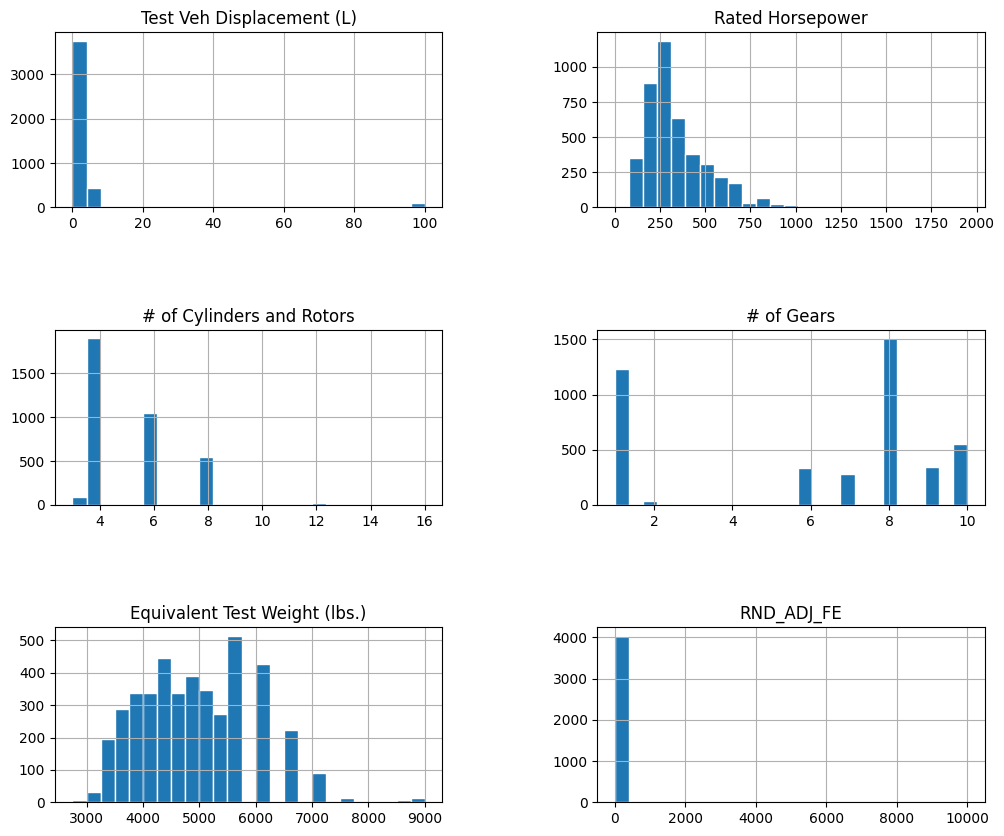

In [6]:
principales = ['Test Veh Displacement (L)', 'Rated Horsepower', '# of Cylinders and Rotors',
               '# of Gears', 'Equivalent Test Weight (lbs.)', 'RND_ADJ_FE']
etiquetas = ['Cilindrada (L)', 'Potencia (HP)', 'Cilindros o rotores',
             'Cantidad de marchas', 'Peso equivalente (lb)', 'Economía declarada (MPG)']

display(datos[principales].describe().round(3))

datos[principales].hist(figsize=(12, 10), bins=25, edgecolor='white')
plt.subplots_adjust(hspace=0.7, wspace=0.4)
plt.show()

El peso equivalente tiene mediana **4.750 lb** y varía entre **2.750 y 9.000 lb**. La potencia tiene mediana **305 HP**, con mínimo **1 HP** y máximo **1.948 HP**. La cilindrada tiene mediana **2,487 L** y máximo **99,999 L**.

La economía tiene mediana **32,9 MPG** y media aproximada **65,0 MPG**. Los valores extremos y la mezcla de combustibles y procedimientos afectan el resumen global; el histograma completo muestra esos extremos, aunque comprima la zona central.

Para observar la economía en un grupo más comparable, se seleccionan los registros de gasolina Tier 2 y un único procedimiento: `Federal fuel 2-day exhaust (w/can load)`. Esta selección crea una vista descriptiva y no modifica la base original.

Registros seleccionados: 922


,Economía (MPG)
count,922.000
mean,29.734
std,11.574
min,9.500
25%,22.500
50%,26.600
75%,33.475
max,82.800


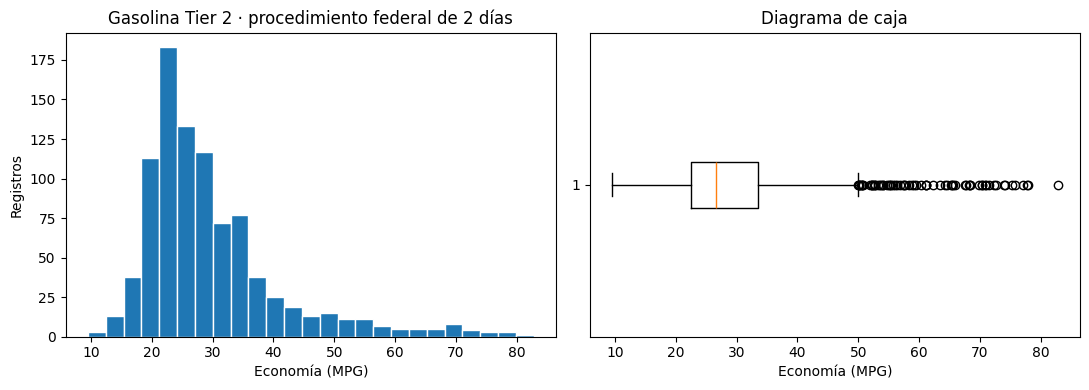

In [7]:
# Seleccionamos un grupo específico para aislar la economía (gasolina Tier 2 y procedimiento federal)
seleccion = (
    (datos['Test Fuel Type Description'] == 'Tier 2 Cert Gasoline') &
    (datos['Test Procedure Description'] == 'Federal fuel 2-day exhaust (w/can load)')
)
contexto = datos.loc[seleccion].copy()
economia = contexto['RND_ADJ_FE'].dropna()

print('Registros seleccionados:', len(contexto))
display(economia.describe().to_frame('Economía (MPG)').round(3))

# Gráficos de distribución y boxplot para el subgrupo
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(economia, bins=25, edgecolor='white')
axes[0].set_xlabel('Economía (MPG)')
axes[0].set_ylabel('Registros')
axes[0].set_title('Gasolina Tier 2 · procedimiento federal de 2 días')

axes[1].boxplot(economia, vert=False)
axes[1].set_xlabel('Economía (MPG)')
axes[1].set_title('Diagrama de caja')
plt.tight_layout()
plt.show()

La selección contiene **922 registros**, con media **29,734 MPG**, mediana **26,6 MPG**, Q1 **22,5 MPG**, Q3 **33,475 MPG** y máximo **82,8 MPG**. El histograma presenta una cola hacia valores altos. Los resúmenes cambian al fijar combustible y procedimiento, lo que justifica considerar ese contexto antes de comparar economías.

### 1.6. Valores extremos

El diagrama de caja señala posibles valores atípicos usando los límites **Q1 − 1,5 × RIC** y **Q3 + 1,5 × RIC**, donde **RIC = Q3 − Q1**. Los bigotes llegan hasta los valores observados más alejados dentro de esos límites. Los puntos exteriores son candidatos a revisión; no son errores confirmados.

Se aplica el criterio al grupo anterior para evitar que la mezcla de ensayos determine los límites. También se muestran las mayores economías de toda la base y se cuentan otros valores llamativos observados durante la exploración.

In [8]:
q1 = economia.quantile(0.25)
q3 = economia.quantile(0.75)
ric = q3 - q1
limite_inferior = q1 - 1.5 * ric
limite_superior = q3 + 1.5 * ric
atipicos = economia[(economia < limite_inferior) | (economia > limite_superior)]
print('Límites del diagrama de caja:', round(limite_inferior, 3), round(limite_superior, 3))
print('Registros candidatos a atípicos en el grupo:', len(atipicos))

columnas_revision = ['Represented Test Veh Model', 'Test Fuel Type Description',
                     'Test Category', 'RND_ADJ_FE']
display(datos.sort_values(by='RND_ADJ_FE', ascending=False)[columnas_revision].head(10))

print('Registros con cilindrada 99.999 L:', (datos['Test Veh Displacement (L)'] == 99.999).sum())
print('Economías iguales al máximo de la base:', (datos['RND_ADJ_FE'] == datos['RND_ADJ_FE'].max()).sum())
print('Economías iguales a cero:', (datos['RND_ADJ_FE'] == 0).sum())
print('Potencias iguales a 1 HP:', (datos['Rated Horsepower'] == 1).sum())
print('Combustibles de los registros con cilindrada 99.999 L:')
print(datos.loc[datos['Test Veh Displacement (L)'] == 99.999,
                 'Test Fuel Type Description'].value_counts())

Límites del diagrama de caja: 6.037 49.938
Registros candidatos a atípicos en el grupo: 68


,Represented Test Veh Model,Test Fuel Type Description,Test Category,RND_ADJ_FE
3021,Utopia,CARB LEV3 E10 Premium Gasoline,FTP,10000.0
2464,Emira,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),HWY,10000.0
2463,Emira,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),FTP,10000.0
3022,Utopia,CARB LEV3 E10 Premium Gasoline,HWY,10000.0
2465,Emira,CARB LEV3 E10 Regular Gasoline,SC03,10000.0
2466,Emira,Cold CO E10 Regular Gasoline (Tier 3),FTP,10000.0
2461,Emira,Cold CO E10 Regular Gasoline (Tier 3),FTP,10000.0
2462,Emira,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),SC03,10000.0
3466,RC F,Cold CO Premium (Tier 2),FTP,4599.1
3460,RC F,Cold CO Premium (Tier 2),FTP,4595.3


Registros con cilindrada 99.999 L: 95
Economías iguales al máximo de la base: 8
Economías iguales a cero: 2
Potencias iguales a 1 HP: 8
Combustibles de los registros con cilindrada 99.999 L:
Test Fuel Type Description
Electricity    95
Name: count, dtype: int64


En el grupo de gasolina y procedimiento común se identifican **68 registros candidatos a atípicos**, con límites aproximados de **6,04 y 49,94 MPG**. Son observaciones para revisar y no registros que deban eliminarse automáticamente.

Hay **95 registros con cilindrada 99,999 L**, todos asociados a electricidad. También se observan **8 economías iguales al máximo 9999.9999999**, dos economías de **4599,1 y 4595,3**, **2 economías cero** y **8 potencias de 1 HP**.

Estos valores requieren verificar si corresponden a convenciones de registro, resultados particulares o inconsistencias. En esta etapa se señalan sin corregirlos ni eliminarlos. Tampoco se eliminan los candidatos identificados por el diagrama de caja.

### 1.7. Conclusiones del inciso 1

La base tiene **4.287 filas y 67 atributos**, con **1.448 configuraciones** y distintos tipos de ensayo. No hay filas idénticas, pero un ensayo o una configuración puede aparecer en más de una fila. Por eso, el tratamiento de las repeticiones debe definirse antes de los análisis posteriores.

Los faltantes dependen en parte del tipo de registro. El caso ADFE muestra que una ausencia puede corresponder a un método que no se utiliza. Otras ausencias requieren revisión, especialmente cuando no se explican por la aplicabilidad del atributo.

Las variables principales presentan distribuciones y extremos que deben interpretarse con el combustible y el procedimiento de ensayo. La economía global resulta afectada por valores muy altos; al considerar gasolina Tier 2 y un procedimiento común, la mediana es **26,6 MPG**.

La exploración deja identificadas las cuestiones para el inciso 2: repeticiones, ausencias y valores extremos. **El Excel original y los valores del DataFrame se conservaron sin correcciones ni imputaciones.**

In [9]:
datos

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.000,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.000,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.000,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.000,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.200,SASXV05.2AMV,Car,...,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4282,2025,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,...,-8.08,-0.0412,0.0213,NaN,NaN,N,NaN,NaN,N,No averaging
4283,2025,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,...,-8.08,-0.0412,0.0213,NaN,NaN,N,NaN,NaN,N,No averaging
4284,2025,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,...,-7.96,0.0127,0.0206,NaN,NaN,N,NaN,NaN,N,No averaging
4285,2025,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,...,-8.08,-0.0412,0.0213,NaN,NaN,N,NaN,NaN,N,No averaging


## 2. Limpieza de la base

### 2.1. Preparación de la copia de trabajo

Creamos `datos_limpios` como una copia de `datos` para hacer la limpieza sin cambiar la base original. Importamos NumPy para poder usar `np.nan`, que representa un valor faltante.

Quitamos diez columnas de esta copia. `Model Year` y `FE_UNIT` tienen el mismo valor en todas las filas. Las otras ocho contienen códigos cuya información también aparece en columnas con descripciones; conservamos esas descripciones para facilitar la lectura.

Al final mostramos el tamaño de ambas bases: la original tiene 67 columnas y la copia queda con 57. Las dos mantienen las 4.287 filas.

In [10]:
import numpy as np

datos_limpios = datos.copy()

columnas_excluir = [
    'Model Year',
    'FE_UNIT',
    'Tested Transmission Type Code',
    'Drive System Code',
    'Transmission Overdrive Code',
    'Shift Indicator Light Use Cd',
    'Test Procedure Cd',
    'Test Fuel Type Cd',
    'Aftertreatment Device Cd',
    'Averaging Method Cd'
]

datos_limpios = datos_limpios.drop(columns=columnas_excluir)
print('Dimensiones originales:', datos.shape)
print('Dimensiones de trabajo:', datos_limpios.shape)

Dimensiones originales: (4287, 67)
Dimensiones de trabajo: (4287, 57)


### 2.2. Comprobación de los registros

Comprobamos si hay filas iguales en todas sus columnas y contamos cuántas configuraciones y números de ensayo distintos siguen presentes. `clave_config` reúne las tres columnas que usamos en el punto 1 para reconocer cada configuración.

El resultado muestra cero filas completamente duplicadas, 1.448 configuraciones y 4.014 números de ensayo distintos. Este bloque solo cuenta y muestra resultados: no elimina filas. Que se repita un número de ensayo no significa que toda la fila esté duplicada.

In [11]:
print('Filas completamente duplicadas:', datos_limpios.duplicated().sum())
print('Configuraciones conservadas:', datos_limpios[clave_config].drop_duplicates().shape[0])
print('Números de ensayo conservados:', len(datos_limpios['Test Number'].value_counts()))

Filas completamente duplicadas: 0
Configuraciones conservadas: 1448
Números de ensayo conservados: 4014


### 2.3. Reemplazo de los valores seleccionados por faltantes

Reemplazamos por `NaN` los valores que seleccionamos para la limpieza: cilindrada de 99,999 L, potencia de 1 HP y economías de 9999,9999999; 4595,3; 4599,1 y cero. `replace()` busca esos valores en cada columna y los cambia por un faltante.

La última línea hace lo mismo con los 68 valores de economía señalados por el diagrama de caja del punto 1. `atipicos.index` permite ubicar las filas correspondientes en la copia. Estos casos pertenecen al grupo de gasolina Tier 2 y al procedimiento federal de dos días que analizamos antes.

Estar fuera de los límites del diagrama no demuestra que un dato sea incorrecto. En esta versión decidimos dejarlos como faltantes para los análisis siguientes; esta decisión queda sujeta a revisión del grupo. Se reemplaza el valor de economía, pero se conserva el resto de cada fila. Los faltantes que ya existían permanecen sin completar.

In [12]:
datos_limpios['Test Veh Displacement (L)'] = datos_limpios['Test Veh Displacement (L)'].replace(99.999, np.nan)
datos_limpios['Rated Horsepower'] = datos_limpios['Rated Horsepower'].replace(1, np.nan)
datos_limpios['RND_ADJ_FE'] = datos_limpios['RND_ADJ_FE'].replace(
    [9999.9999999, 4595.3, 4599.1, 0], np.nan
)
datos_limpios.loc[atipicos.index, 'RND_ADJ_FE'] = np.nan

### 2.4. Resumen de la limpieza

Armamos una tabla para comparar cuántos faltantes había antes y cuántos hay después en las tres columnas modificadas. La diferencia indica cuántos valores reemplazamos por `NaN`.

Se reemplazaron 95 valores de cilindrada, 8 de potencia y 80 de economía: 183 en total. Los 80 de economía incluyen los 68 señalados por el diagrama de caja. Esa columna pasa de 221 a 301 faltantes.

Por último, comprobamos que siguen presentes las 4.287 filas y mostramos las primeras filas de `datos_limpios` para revisar cómo quedó la base.

In [13]:
columnas_corregidas = ['Test Veh Displacement (L)', 'Rated Horsepower', 'RND_ADJ_FE']
resumen_limpieza = pd.DataFrame({
    'Nulos originales': datos[columnas_corregidas].isna().sum(),
    'Nulos finales': datos_limpios[columnas_corregidas].isna().sum()
})
resumen_limpieza['Reemplazos por NaN'] = resumen_limpieza['Nulos finales'] - resumen_limpieza['Nulos originales']
display(resumen_limpieza)
print('Total de valores reemplazados:', resumen_limpieza['Reemplazos por NaN'].sum())
print('Filas conservadas:', len(datos_limpios))
display(datos_limpios.head())

,Nulos originales,Nulos finales,Reemplazos por NaN
Test Veh Displacement (L),0,95,95
Rated Horsepower,0,8,8
RND_ADJ_FE,221,301,80


Total de valores reemplazados: 183
Filas conservadas: 4287


,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,...,Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averging Method Desc
0,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680.0,...,0.2228,0.0221,5.67,0.0083,0.0221,Three-way catalyst,N,NaN,NaN,No averaging
1,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680.0,...,0.2228,0.0221,5.67,0.0083,0.0221,Three-way catalyst,N,NaN,NaN,No averaging
2,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707.0,...,-0.3286,0.0373,-4.88,-0.5318,0.0367,Three-way catalyst,N,NaN,NaN,No averaging
3,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707.0,...,-0.3286,0.0373,-4.88,-0.5318,0.0367,Three-way catalyst,N,NaN,NaN,No averaging
4,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,825.0,...,0.3527,0.0226,-0.57,-0.0029,0.0128,Three-way catalyst,N,NaN,NaN,No averaging


## 3. Hipótesis propuestas

Pendiente de desarrollo. Se formularán una hipótesis univariada, una bivariada y una multivariada, con su justificación de dominio.

## 4. Validación de hipótesis

Pendiente de desarrollo. Se evaluarán las tres hipótesis propuestas y las tres indicadas en el enunciado. Para cada una se presentarán la técnica elegida, sus condiciones de aplicación, los resultados y la conclusión.